In [6]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("libraries loaded successfully!")

libraries loaded successfully!


In [7]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
df = pd.read_excel("Dataset for Data Analytics.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [13]:
df.shape

(1200, 14)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   str           
 1   Date             1200 non-null   datetime64[us]
 2   CustomerID       1200 non-null   str           
 3   Product          1200 non-null   str           
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   str           
 7   PaymentMethod    1200 non-null   str           
 8   OrderStatus      1200 non-null   str           
 9   TrackingNumber   1200 non-null   str           
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       891 non-null    str           
 12  ReferralSource   1200 non-null   str           
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(9)


In [15]:
df.isnull().sum(

OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64

In [18]:
data = df.copy()
print("data copy created successfully!")

data copy created successfully!


In [19]:
data.duplicated().sum()

np.int64(0)

In [21]:
data["OrderID"].duplicated().sum()

np.int64(0)

In [23]:
data["CouponCode"] = data["CouponCode"].fillna("No Coupon")

print("Missing coupon values handled successfully.")

Missing coupon values handled successfully.


In [24]:
data.isnull().sum()

OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64

In [25]:
data[["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]].describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [26]:
data["CalculatedTotal"] = (
    data["Quantity"] * data["UnitPrice"]
)

data["PriceDifference"] = (
    data["TotalPrice"] - data["CalculatedTotal"]
)

data["PriceDifference"].abs().describe()

count    1.200000e+03
mean     2.019126e-14
std      7.665916e-14
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      4.547474e-13
Name: PriceDifference, dtype: float64

In [27]:
customer_spending = data.groupby("CustomerID").agg(
    Total_Spending=("TotalPrice", "sum"),
    Average_Order_Value=("TotalPrice", "mean")
).reset_index()

customer_spending.head()

,CustomerID,Total_Spending,Average_Order_Value
0,C10002,1470.03,1470.03
1,C10054,153.48,153.48
2,C10126,1349.80,1349.80
3,C10154,1303.04,1303.04
4,C10211,635.90,635.90


In [28]:
customer_behavior = data.groupby("CustomerID").agg(
    Total_Quantity=("Quantity", "sum"),
    Average_Items_In_Cart=("ItemsInCart", "mean"),
    Unique_Products=("Product", "nunique"),
    Coupon_Usage=("CouponCode", lambda x: (x != "No Coupon").sum())
).reset_index()

customer_behavior.head()

,CustomerID,Total_Quantity,Average_Items_In_Cart,Unique_Products,Coupon_Usage
0,C10002,3,4.0,1,1
1,C10054,2,7.0,1,1
2,C10126,2,4.0,1,1
3,C10154,4,8.0,1,1
4,C10211,5,10.0,1,1


In [30]:
customer_orders = data.groupby("CustomerID").agg(
    Total_Orders=("OrderID", "count")
).reset_index()

customer_orders.head()

,CustomerID,Total_Orders
0,C10002,1
1,C10054,1
2,C10126,1
3,C10154,1
4,C10211,1


In [31]:
customer_spending = data.groupby("CustomerID").agg(
    Total_Spending=("TotalPrice", "sum"),
    Average_Order_Value=("TotalPrice", "mean")
).reset_index()

customer_spending.head()

,CustomerID,Total_Spending,Average_Order_Value
0,C10002,1470.03,1470.03
1,C10054,153.48,153.48
2,C10126,1349.80,1349.80
3,C10154,1303.04,1303.04
4,C10211,635.90,635.90


In [32]:
customer_behavior = data.groupby("CustomerID").agg(
    Total_Quantity=("Quantity", "sum"),
    Average_Items_In_Cart=("ItemsInCart", "mean"),
    Unique_Products=("Product", "nunique"),
    Coupon_Usage=("CouponCode", lambda x: (x != "No Coupon").sum())
).reset_index()

customer_behavior.head()

,CustomerID,Total_Quantity,Average_Items_In_Cart,Unique_Products,Coupon_Usage
0,C10002,3,4.0,1,1
1,C10054,2,7.0,1,1
2,C10126,2,4.0,1,1
3,C10154,4,8.0,1,1
4,C10211,5,10.0,1,1


In [33]:
customer_data = customer_orders.merge(
    customer_spending, on="CustomerID"
)

customer_data = customer_data.merge(
    customer_behavior, on="CustomerID"
)

customer_data.head()

,CustomerID,Total_Orders,Total_Spending,Average_Order_Value,Total_Quantity,Average_Items_In_Cart,Unique_Products,Coupon_Usage
0,C10002,1,1470.03,1470.03,3,4.0,1,1
1,C10054,1,153.48,153.48,2,7.0,1,1
2,C10126,1,1349.80,1349.80,2,4.0,1,1
3,C10154,1,1303.04,1303.04,4,8.0,1,1
4,C10211,1,635.90,635.90,5,10.0,1,1


In [34]:
features = [
    "Total_Orders",
    "Total_Spending",
    "Average_Order_Value",
    "Total_Quantity",
    "Average_Items_In_Cart",
    "Unique_Products",
    "Coupon_Usage"
]

X = customer_data[features]

X.head()

,Total_Orders,Total_Spending,Average_Order_Value,Total_Quantity,Average_Items_In_Cart,Unique_Products,Coupon_Usage
0,1,1470.03,1470.03,3,4.0,1,1
1,1,153.48,153.48,2,7.0,1,1
2,1,1349.80,1349.80,2,4.0,1,1
3,1,1303.04,1303.04,4,8.0,1,1
4,1,635.90,635.90,5,10.0,1,1


In [39]:
from sklearn.preprocessing import StandardScaler

In [40]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization completed!")

Standardization completed!


In [41]:
X_scaled[:5]

array([[-0.09663261,  0.49000037,  0.50689696,  0.01879061, -0.65501174,
        -0.08230383,  0.56579196],
       [-0.09663261, -1.09772449, -1.10302603, -0.67939786,  0.66463066,
        -0.08230383,  0.56579196],
       [-0.09663261,  0.34500613,  0.35987555, -0.67939786, -0.65501174,
        -0.08230383,  0.56579196],
       [-0.09663261,  0.28861479,  0.3026958 ,  0.71697908,  1.10451146,
        -0.08230383,  0.56579196],
       [-0.09663261, -0.51593859, -0.51310613,  1.41516755,  1.98427306,
        -0.08230383,  0.56579196]])

In [42]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA completed successfully!")

PCA completed successfully!


In [43]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total explained variance:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.41009368 0.2704394 ]
Total explained variance:
0.6805330754014971


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


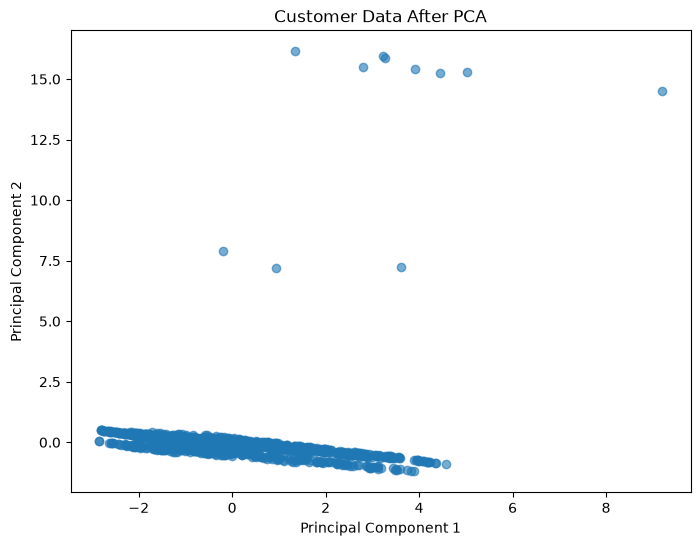

In [46]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Data After PCA")

plt.show()

In [47]:
inertia = []

K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

print(inertia)

[8323.000000000004, 5944.369075589742, 3871.4411385187154, 3069.1356237285563, 2482.8200897063953, 2163.4999255143557, 1929.9221101055832, 1602.0640635089435, 1425.968942978365, 1272.1029904413851]


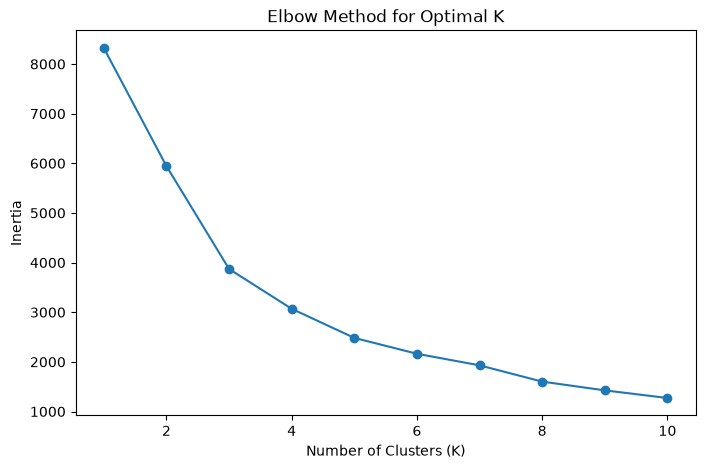

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(K, inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.show()

In [49]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print("Clusters:", k, "Silhouette Score:", score)

Clusters: 2 Silhouette Score: 0.34908761724276627
Clusters: 3 Silhouette Score: 0.3569104687733333
Clusters: 4 Silhouette Score: 0.3565096162893789
Clusters: 5 Silhouette Score: 0.33268427607597967
Clusters: 6 Silhouette Score: 0.35410752913063565
Clusters: 7 Silhouette Score: 0.3489639935885812
Clusters: 8 Silhouette Score: 0.3524568257664861
Clusters: 9 Silhouette Score: 0.35647288719790254
Clusters: 10 Silhouette Score: 0.32551674306891576


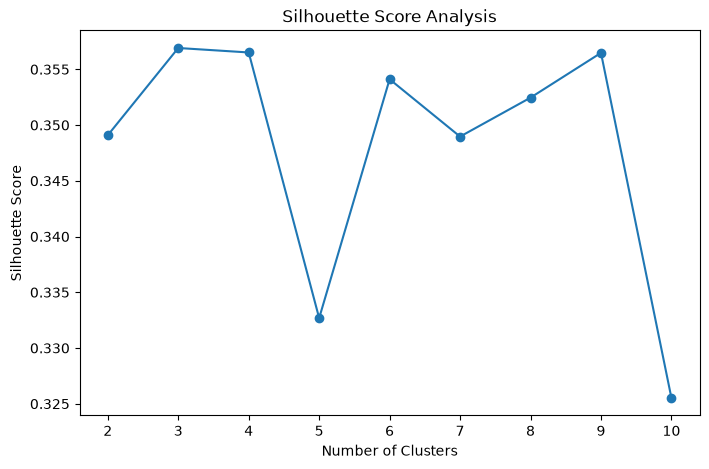

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Analysis")

plt.show()

In [51]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

customer_data.head()

,CustomerID,Total_Orders,Total_Spending,Average_Order_Value,Total_Quantity,Average_Items_In_Cart,Unique_Products,Coupon_Usage,Cluster
0,C10002,1,1470.03,1470.03,3,4.0,1,1,0
1,C10054,1,153.48,153.48,2,7.0,1,1,0
2,C10126,1,1349.80,1349.80,2,4.0,1,1,0
3,C10154,1,1303.04,1303.04,4,8.0,1,1,1
4,C10211,1,635.90,635.90,5,10.0,1,1,1


In [52]:
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer segmentation completed!")

Customer segmentation completed!


In [53]:
customer_data["Cluster"].value_counts().sort_index()

Cluster
0    744
1    437
2      8
Name: count, dtype: int64

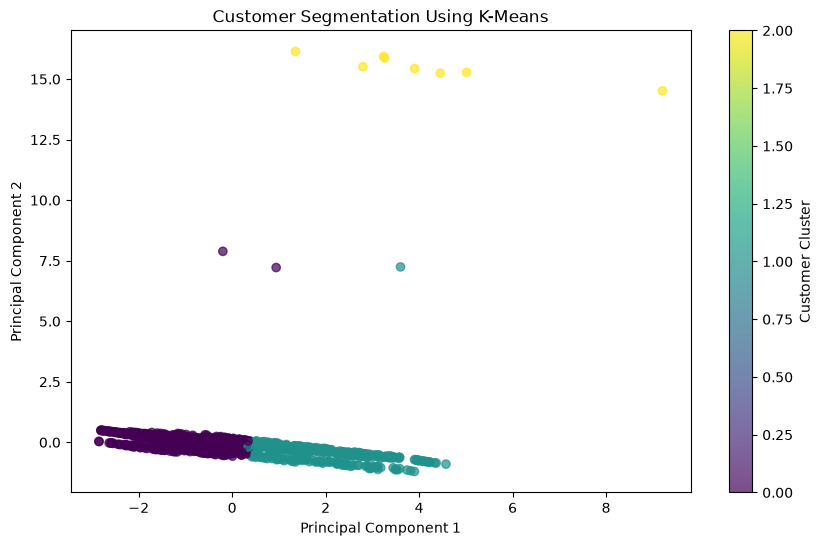

In [54]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=customer_data["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation Using K-Means")
plt.colorbar(label="Customer Cluster")

plt.show()

In [55]:
cluster_profile = customer_data.groupby("Cluster")[features].mean().round(2)

cluster_profile

,Total_Orders,Total_Spending,Average_Order_Value,Total_Quantity,Average_Items_In_Cart,Unique_Products,Coupon_Usage
Cluster,,,,,,,
0,1.0,559.06,557.80,2.21,4.57,1.0,0.74
1,1.0,1908.49,1905.23,4.21,7.05,1.0,0.76
2,2.0,1851.53,925.76,6.12,5.25,2.0,1.38


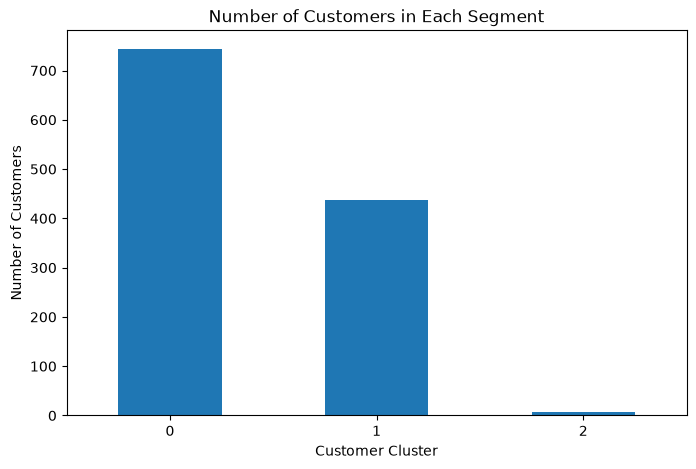

In [56]:
cluster_counts = customer_data["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.title("Number of Customers in Each Segment")

plt.xticks(rotation=0)
plt.show()

In [57]:
print("CUSTOMER SEGMENTATION SUMMARY")

print("\nNumber of customers in each cluster:")
print(customer_data["Cluster"].value_counts().sort_index())

print("\nCustomer cluster profiles:")
display(cluster_profile)

CUSTOMER SEGMENTATION SUMMARY

Number of customers in each cluster:
Cluster
0    744
1    437
2      8
Name: count, dtype: int64

Customer cluster profiles:


,Total_Orders,Total_Spending,Average_Order_Value,Total_Quantity,Average_Items_In_Cart,Unique_Products,Coupon_Usage
Cluster,,,,,,,
0,1.0,559.06,557.80,2.21,4.57,1.0,0.74
1,1.0,1908.49,1905.23,4.21,7.05,1.0,0.76
2,2.0,1851.53,925.76,6.12,5.25,2.0,1.38


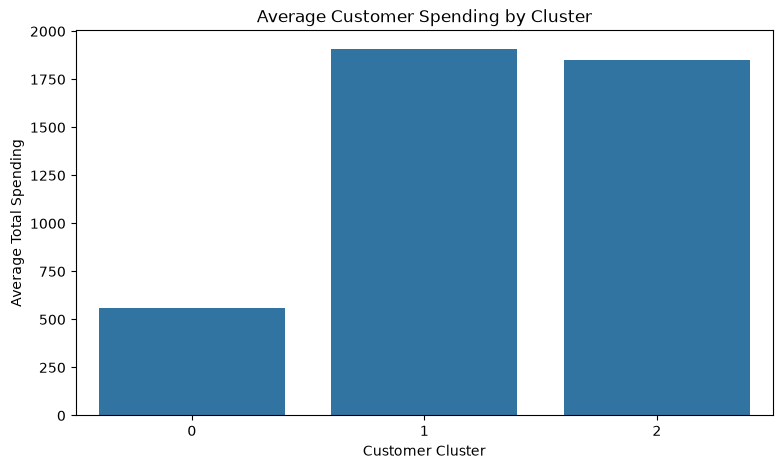

In [58]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_data,
    x="Cluster",
    y="Total_Spending",
    errorbar=None
)

plt.title("Average Customer Spending by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Total Spending")

plt.show()

In [59]:
customer_data.to_csv(
    "Customer_Segmentation_Results.csv",
    index=False
)

cluster_profile.to_csv(
    "Customer_Cluster_Profiles.csv"
)

print("Project results saved successfully!")

Project results saved successfully!
